# 06 – Predicting early termination of Phase I trials (research question 4)

**Prediction target (D51):** terminated **within 3 years after the start date** – all trials started
2005–2020 (any status except *Withdrawn*), so that every trial has the same observation time
(no right-censoring). Trials still running or with status *unknown* and trials terminated later
than 3 years count as "not terminated within 3 years" – the model predicts **early** termination.
The outcome of the analysis set (Completed vs. Terminated) is only used as a sensitivity variant.

| Part | Content | Block |
|---|---|---|
| A | cohort, leakage check, correlations (D30), placebo finding (D50), data split, baseline | B15 |
| B | logistic regression and random forest, class weights, PR-AUC | B16 |
| C | threshold, confusion matrix, feature importance, interpretation | B17 |

Only features **known at the start** of a trial are used (✅); site/country features (⚠️) in a
separate variant; post-start information (❌) is excluded.

In [1]:
# --- Setup -------------------------------------------------------------------
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import viz_style as vs

vs.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_DIR / "data" / "processed"
FIGURES = PROJECT_DIR / "figures"
SEED = 2026

## A1. Cohort and prediction target

In [2]:
win = pd.read_parquet(PROCESSED / "ctgov_window_dataset.parquet")
reasons = pd.read_parquet(PROCESSED / "why_stopped_final.parquet")[["nct_id", "primary_reason_final", "safety_related_final"]]
cohort = win[(win["start_year"] <= 2020) & (win["overall_status"] != "WITHDRAWN")].merge(reasons, on="nct_id", how="left")

end_date = cohort["completion_date_dt"].fillna(cohort["primary_completion_date_dt"])
cohort["days_to_end"] = (end_date - cohort["start_date_dt"]).dt.days
assert not ((cohort["terminated"] == 1) & cohort["days_to_end"].isna()).any()
cohort["y"] = ((cohort["terminated"] == 1) & (cohort["days_to_end"] <= 3 * 365.25)).astype(int)
cohort["oncology"] = (cohort["indication_group"] == "Oncology").astype(int)

prev = cohort["y"].mean()
print(f"Cohort: {len(cohort):,} trials started 2005–2020 (incl. 2016), any status except Withdrawn")
print(f"Terminated within 3 years: {cohort['y'].sum():,} ({prev:.1%})  – PR-AUC of a random model ≈ {prev:.3f}")
print(cohort["overall_status"].value_counts().to_string())

Cohort: 7,874 trials started 2005–2020 (incl. 2016), any status except Withdrawn
Terminated within 3 years: 543 (6.9%)  – PR-AUC of a random model ≈ 0.069
overall_status
COMPLETED                  6228
TERMINATED                  965
UNKNOWN                     403
ACTIVE_NOT_RECRUITING       192
RECRUITING                   67
SUSPENDED                    17
ENROLLING_BY_INVITATION       2


## A2. Features and leakage check

Feature list from the leakage classification of Block 6 (`docs/data_dictionary.md`).

In [3]:
CAT = ["indication_group", "sponsor_group", "intervention_model", "primary_purpose_group", "has_dmc_cat"]
BIN = ["healthy_volunteers", "includes_children", "male_only", "phase_1_2", "randomized", "blinded",
       "placebo", "biological", "drug", "industry_collaborator"]
ORD = ["masking_level"]
YEAR = ["start_year"]
SITE = ["multinational", "site_outside_europe", "site_in_us", "log_n_locations", "log_n_countries"]   # ⚠️
EXCLUDED = ["enrollment_actual", "registered_after_completion", "registered_prospectively",
            "has_results_posted", "completion_date", "primary_completion_date", "overall_status",
            "why_stopped", "last_update_post_date", "status_verified_date"]                          # ❌

FEATURE_SETS = {
    "core (✅)": CAT + BIN + ORD,
    "core + start year": CAT + BIN + ORD + YEAR,
    "core + start year + ⚠️ site": CAT + BIN + ORD + YEAR + SITE,
}
leak_table = pd.DataFrame(
    [(f, "✅ known at start", "model") for f in CAT + BIN + ORD + YEAR] +
    [(f, "⚠️ may be updated after start", "variant") for f in SITE] +
    [(f, "❌ post-start / outcome-related", "excluded") for f in EXCLUDED],
    columns=["feature", "assessment", "use"])
leak_table

,feature,assessment,use
0,indication_group,✅ known at start,model
1,sponsor_group,✅ known at start,model
2,intervention_model,✅ known at start,model
3,primary_purpose_group,✅ known at start,model
4,has_dmc_cat,✅ known at start,model
5,healthy_volunteers,✅ known at start,model
6,includes_children,✅ known at start,model
7,male_only,✅ known at start,model
8,phase_1_2,✅ known at start,model
9,randomized,✅ known at start,model


In [4]:
# Automatic check: single-feature ROC-AUC (a feature that alone predicts almost perfectly is suspicious)
def single_auc(col):
    x = cohort[col]
    if not pd.api.types.is_numeric_dtype(x):          # categorical/text: use the outcome rate per level
        x = x.map(cohort.groupby(col)["y"].mean())
    x = pd.to_numeric(x, errors="coerce").astype(float)
    x = x.fillna(x.median())
    auc = roc_auc_score(cohort["y"], x)
    return max(auc, 1 - auc)


auc_check = pd.Series({c: single_auc(c) for c in CAT + BIN + ORD + YEAR + SITE + ["registered_after_completion"]},
                      name="single-feature AUC").sort_values(ascending=False)
print("Flag if AUC > 0.75 (possible leakage):", list(auc_check[auc_check > 0.75].index) or "none")
auc_check.round(3).to_frame()

Flag if AUC > 0.75 (possible leakage): none


,single-feature AUC
intervention_model,0.573
start_year,0.570
indication_group,0.562
multinational,0.555
log_n_locations,0.550
log_n_countries,0.547
placebo,0.545
sponsor_group,0.542
healthy_volunteers,0.541
site_outside_europe,0.534


## A3. Correlations between features (D30)

* binary / ordinal / numeric pairs: Spearman correlation (for two binary features = phi coefficient)
* categorical features: Cramér's V with every other feature
* VIF from the design matrix of the full logistic model

In [5]:
num_cols = BIN + ORD + YEAR + SITE + ["oncology"]
corr = cohort[num_cols].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "feature 1", "level_1": "feature 2"}))
pairs["abs"] = pairs["spearman"].abs()
strong = pairs[pairs["abs"] >= 0.4].sort_values("abs", ascending=False).drop(columns="abs")
print(f"Pairs with |r| ≥ 0.4: {len(strong)}")
strong.round(2)

Pairs with |r| ≥ 0.4: 31


,feature 1,feature 2,spearman
100,blinded,masking_level,0.98
232,multinational,log_n_countries,0.98
248,site_outside_europe,site_in_us,0.92
286,log_n_locations,log_n_countries,0.85
250,site_outside_europe,log_n_countries,0.85
231,multinational,log_n_locations,0.83
229,multinational,site_outside_europe,0.83
118,placebo,masking_level,0.81
96,blinded,placebo,0.80
268,site_in_us,log_n_countries,0.78


In [6]:
def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    return np.sqrt(chi2 / (n * (min(tab.shape) - 1)))


cv_rows = []
for c in CAT:
    for other in CAT + BIN + ["oncology"]:
        if other != c and not (other in CAT and CAT.index(other) < CAT.index(c)):
            cv_rows.append({"categorical": c, "other": other, "cramers_v": cramers_v(cohort[c], cohort[other])})
cv = pd.DataFrame(cv_rows).sort_values("cramers_v", ascending=False)
cv[cv["cramers_v"] >= 0.3].round(2)

,categorical,other,cramers_v
14,indication_group,oncology,1.00
4,indication_group,healthy_volunteers,0.74
35,intervention_model,randomized,0.66
8,indication_group,randomized,0.52
9,indication_group,blinded,0.47
43,primary_purpose_group,healthy_volunteers,0.45
36,intervention_model,blinded,0.42
10,indication_group,placebo,0.41
41,intervention_model,oncology,0.40
31,intervention_model,healthy_volunteers,0.39


Saved figure: diag_feature_correlations.png


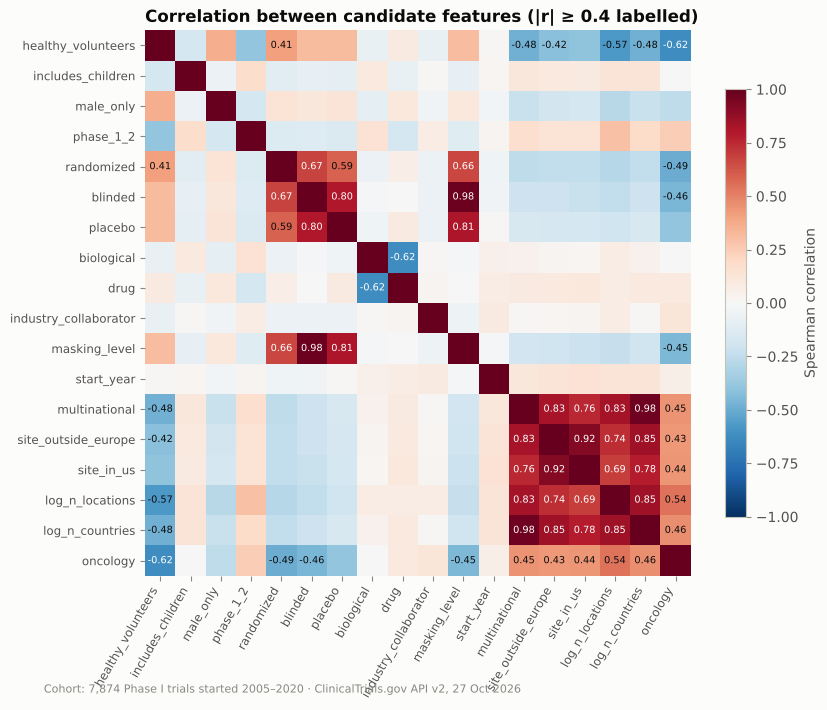

In [7]:
fig, ax = plt.subplots(figsize=(8.8, 7.4))
ax.grid(False)
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=8.5)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        if i != j and abs(corr.values[i, j]) >= 0.4:
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="#ffffff" if abs(corr.values[i, j]) > 0.6 else vs.INK_PRIMARY)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman correlation")
ax.set_title("Correlation between candidate features (|r| ≥ 0.4 labelled)")
vs.source_note(fig, f"Cohort: {len(cohort):,} Phase I trials started 2005–2020 · ClinicalTrials.gov API v2, 27 Oct 2026", y=-0.02)
vs.save(fig, FIGURES / "diag_feature_correlations.png")
plt.show()

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
formula = ("y ~ " + " + ".join([f"C({c})" for c in CAT] + BIN + ORD + YEAR + SITE))
m_full = smf.logit(formula, data=cohort).fit(disp=False, maxiter=300)
X = m_full.model.exog
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=m_full.model.exog_names[1:])
vif.index = vif.index.str.replace(r"C\((\w+)\)\[T\.(.*)\]", r"\1: \2", regex=True)
print(f"VIF > 5: {list(vif[vif > 5].round(1).items()) or 'none'}")
vif.sort_values(ascending=False).round(2).head(12).to_frame("VIF")

VIF > 5: [('indication_group: Healthy volunteers – no target condition', 6.4), ('indication_group: Oncology', 8.6), ('blinded', 7.1), ('masking_level', 5.6), ('multinational', 5.2), ('site_outside_europe', 8.7), ('site_in_us', 6.6), ('log_n_locations', 5.6), ('log_n_countries', 6.4)]


,VIF
site_outside_europe,8.74
indication_group: Oncology,8.61
blinded,7.12
site_in_us,6.58
log_n_countries,6.44
indication_group: Healthy volunteers – no target condition,6.36
log_n_locations,5.63
masking_level,5.56
multinational,5.17
intervention_model: SINGLE_GROUP,3.48


## A4. The placebo finding (D50)

In Block 13, placebo-controlled trials had an adjusted OR of 2.01 for termination. Is this a
genuine association or a by-product of correlated design features?

In [9]:
print("Placebo share by population and phase:")
print(cohort.groupby(["healthy_volunteers", "phase_1_2"])["placebo"].agg(["size", "mean"]).round(3)
      .rename(columns={"size": "trials", "mean": "share placebo"}))
print("\nPlacebo vs. randomised / blinded (row %):")
print((pd.crosstab(cohort["placebo"], [cohort["randomized"], cohort["blinded"]], normalize="index") * 100).round(1))

Placebo share by population and phase:
                              trials  share placebo
healthy_volunteers phase_1_2                       
0                  0            2676          0.149
                   1            1815          0.126
1                  0            3199          0.418
                   1             184          0.418

Placebo vs. randomised / blinded (row %):
randomized     0          1      
blinded        0    1     0     1
placebo                          
0           67.9  0.7  22.2   9.1
1            1.0  0.7   3.6  94.7


In [10]:
strata = []
for hv, pop in [(1, "Healthy volunteers"), (0, "Patients")]:
    for onc in ([0] if hv == 1 else [1, 0]):
        g = cohort[(cohort["healthy_volunteers"] == hv) & (cohort["oncology"] == onc)]
        for pl in [0, 1]:
            s = g[g["placebo"] == pl]
            strata.append({"population": pop + (" – oncology" if onc else (" – non-oncology" if hv == 0 else "")),
                           "placebo": pl, "trials": len(s), "terminated ≤ 3 y %": round(100 * s["y"].mean(), 1),
                           "median sites": float(s["n_locations"].median()),
                           "randomised %": round(100 * s["randomized"].mean(), 1)})
pd.DataFrame(strata)

,population,placebo,trials,terminated ≤ 3 y %,median sites,randomised %
0,Healthy volunteers,0,1914,3.0,1.0,54.6
1,Healthy volunteers,1,1400,9.2,1.0,98.4
2,Patients – oncology,0,2714,8.2,7.0,13.1
3,Patients – oncology,1,77,16.9,11.0,90.9
4,Patients – non-oncology,0,1149,6.4,1.0,35.7
5,Patients – non-oncology,1,551,7.8,2.0,98.9


In [11]:
base = f"C(indication_group) + healthy_volunteers + phase_1_2 + randomized + blinded + biological + C(sponsor_group) + start_year"
res_pl = smf.logit(f"y ~ placebo + {base}", data=cohort).fit(disp=False, maxiter=300)
res_pl_site = smf.logit(f"y ~ placebo + {base} + multinational + log_n_locations", data=cohort).fit(disp=False, maxiter=300)
res_int = smf.logit(f"y ~ placebo * healthy_volunteers + {base}", data=cohort).fit(disp=False, maxiter=300)


def or_ci(res, term):
    return f"{np.exp(res.params[term]):.2f} ({np.exp(res.conf_int().loc[term, 0]):.2f}–{np.exp(res.conf_int().loc[term, 1]):.2f})"


print("Placebo, adjusted (3-year window cohort)          :", or_ci(res_pl, "placebo"))
print("Placebo, adjusted + multinational + number of sites:", or_ci(res_pl_site, "placebo"))
b, V = res_int.params, res_int.cov_params()
for name, terms in [("placebo – patients", ["placebo"]), ("placebo – healthy volunteers", ["placebo", "placebo:healthy_volunteers"])]:
    est = sum(b[t] for t in terms); se = np.sqrt(sum(V.loc[t1, t2] for t1 in terms for t2 in terms))
    print(f"{name:<29}: {np.exp(est):.2f} ({np.exp(est - 1.96 * se):.2f}–{np.exp(est + 1.96 * se):.2f})")
print(f"interaction p = {res_int.pvalues['placebo:healthy_volunteers']:.3f}")

Placebo, adjusted (3-year window cohort)          : 2.40 (1.60–3.60)
Placebo, adjusted + multinational + number of sites: 2.41 (1.60–3.62)
placebo – patients           : 1.61 (0.99–2.61)
placebo – healthy volunteers : 3.35 (2.11–5.32)
interaction p = 0.002


## A5. Data split

* **Main evaluation:** stratified 5-fold cross-validation, repeated 3 times (different shuffles),
  on the whole cohort – stable estimates despite few positive cases.
* **Robustness:** temporal split – training on trials started 2005–2015, test on 2017–2020
  (2016 left out as a gap), both with the 3-year window outcome. The start year is a weak proxy
  for calendar time and cannot extrapolate to unseen years, so the temporal test is run **with and
  without** the start year.

In [12]:
from sklearn.model_selection import RepeatedStratifiedKFold
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
train_t = cohort[cohort["start_year"] <= 2015]
test_t = cohort[(cohort["start_year"] >= 2017) & (cohort["start_year"] <= 2020)]
split_info = pd.DataFrame([
    {"set": "whole cohort (CV)", "years": "2005–2020", "trials": len(cohort), "positives": int(cohort["y"].sum()),
     "terminated ≤ 3 y %": round(100 * cohort["y"].mean(), 1)},
    {"set": "temporal – training", "years": "2005–2015", "trials": len(train_t), "positives": int(train_t["y"].sum()),
     "terminated ≤ 3 y %": round(100 * train_t["y"].mean(), 1)},
    {"set": "temporal – test", "years": "2017–2020", "trials": len(test_t), "positives": int(test_t["y"].sum()),
     "terminated ≤ 3 y %": round(100 * test_t["y"].mean(), 1)},
])
split_info.to_csv(PROCESSED / "table_model_splits.csv", index=False)
split_info

,set,years,trials,positives,terminated ≤ 3 y %
0,whole cohort (CV),2005–2020,7874,543,6.9
1,temporal – training,2005–2015,4925,281,5.7
2,temporal – test,2017–2020,2378,228,9.6


## A6. Baselines

* **Random model** (`DummyClassifier`, predicts the prevalence): PR-AUC ≈ prevalence, ROC-AUC 0.5.
* **Rule of thumb:** logistic regression with three features a reviewer would think of first –
  oncology, healthy volunteers, Phase 1/2. Any model in Block 16 has to beat this.

In [13]:
def make_pipe(features, model):
    cats = [f for f in features if f in CAT]
    nums = [f for f in features if f not in CAT]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cats),
                             ("num", StandardScaler(), nums)])
    return Pipeline([("pre", pre), ("model", model)])


SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}
base_rows = []
for name, feats, model in [
        ("Random (prevalence)", ["oncology"], DummyClassifier(strategy="prior")),
        ("Rule of thumb: oncology + healthy volunteers + Phase 1/2", ["oncology", "healthy_volunteers", "phase_1_2"],
         LogisticRegression(max_iter=1000))]:
    cv_res = cross_validate(make_pipe(feats, model), cohort[feats], cohort["y"], cv=CV, scoring=SCORING)
    pipe = make_pipe(feats, model).fit(train_t[feats], train_t["y"])
    p_test = pipe.predict_proba(test_t[feats])[:, 1]
    base_rows.append({"model": name,
                      "CV PR-AUC": f"{cv_res['test_pr_auc'].mean():.3f} ± {cv_res['test_pr_auc'].std():.3f}",
                      "CV ROC-AUC": f"{cv_res['test_roc_auc'].mean():.3f} ± {cv_res['test_roc_auc'].std():.3f}",
                      "temporal PR-AUC": round(average_precision_score(test_t["y"], p_test), 3),
                      "temporal ROC-AUC": round(roc_auc_score(test_t["y"], p_test), 3)})
baselines = pd.DataFrame(base_rows)
baselines.to_csv(PROCESSED / "table_model_baselines.csv", index=False)
baselines

,model,CV PR-AUC,CV ROC-AUC,temporal PR-AUC,temporal ROC-AUC
0,Random (prevalence),0.069 ± 0.000,0.500 ± 0.000,0.096,0.50
1,Rule of thumb: oncology + healthy volunteers +...,0.079 ± 0.003,0.553 ± 0.017,0.098,0.52


In [14]:
cohort.to_parquet(PROCESSED / "model_cohort.parquet", index=False)
print(f"Saved model cohort: {len(cohort):,} rows")

Saved model cohort: 7,874 rows


In [15]:
# Design profile of placebo vs. non-placebo trials in healthy volunteers (for the interpretation of D50)
hv = cohort[cohort["healthy_volunteers"] == 1]
print((pd.crosstab(hv["placebo"], hv["intervention_model"], normalize="index") * 100).round(1))
print("\nPrimary reasons of early terminations in healthy-volunteer trials (counts):")
print(pd.crosstab(hv.loc[hv["y"] == 1, "primary_reason_final"], hv.loc[hv["y"] == 1, "placebo"]))

intervention_model  CROSSOVER  FACTORIAL  NOT_REPORTED  PARALLEL  SEQUENTIAL  SINGLE_GROUP
placebo                                                                                   
0                        38.8        0.6           0.4      26.9         3.9          29.3
1                        24.4        1.0           0.9      56.5        10.8           6.4

Primary reasons of early terminations in healthy-volunteer trials (counts):
placebo                          0   1
primary_reason_final                  
COVID-19                         5   5
Efficacy/Futility                5  12
Not stated                      14  24
Other                           12  27
Recruitment                      5   4
Safety                           8  18
Sponsor decision (unspecified)   2  13
Strategic/Business              11  27


## A7. Summary of Part A (Block 15)

**Cohort and target (D51):** 7,874 trials started 2005–2020; **543 (6.9 %) terminated within 3
years** – random-model PR-AUC ≈ 0.069. Temporal split: training 2005–2015 5.7 % (281 / 4,925),
test 2017–2020 **9.6 %** (228 / 2,378) – the prevalence shift between periods (Block 13) also
shows up in the window outcome.

**Leakage check:** feature list as classified in Block 6; no single feature reaches a suspicious
AUC (all ≤ 0.57). The weak single-feature signal already indicates that early termination is hard
to predict from registry data alone.

**Correlations (D30):** strongly redundant pairs – `blinded`/`masking_level` (r = 0.98),
`multinational`/`log_n_countries` (0.98), `site_outside_europe`/`site_in_us` (0.92),
`log_n_locations`/`log_n_countries` (0.85); a design cluster `placebo`–`blinded`–`randomized`
(0.59–0.81); `healthy_volunteers`–`oncology` (−0.62). VIF > 5 for these and for the large
indication groups. → **D52**: for logistic regression a reduced set without `masking_level`,
`log_n_countries`, `site_in_us` and `site_outside_europe`; coefficients of the design cluster are
interpreted jointly, not one by one. Random forest uses all features.

**Placebo finding (D50):** placebo-controlled trials are almost always randomised and
double-blind (94.7 %). The association is concentrated in **healthy-volunteer trials**: early
termination 9.2 % with vs. 3.0 % without placebo; adjusted OR 3.35 (2.11–5.32) vs. 1.61
(0.99–2.61) in patient trials, interaction p = 0.002; unchanged after adjusting for multinational
status and number of sites (median 1 site in both groups – not a size effect).
**Interpretation:** in healthy volunteers, "placebo-controlled" mainly marks randomised,
double-blind **(dose-escalation) studies of new compounds early in development** (more sequential
designs: 10.8 % vs. 3.9 %), whereas trials without placebo are often open-label crossover PK,
bioequivalence or interaction studies of known drugs (crossover 38.8 % vs. 24.4 %). The higher
termination risk reflects **early-development attrition** (strategic, safety, efficacy, sponsor
decisions), not an effect of the placebo itself.

**Baselines:** random model PR-AUC 0.069 (CV), rule of thumb (oncology + healthy volunteers +
Phase 1/2) PR-AUC 0.079 / ROC-AUC 0.55 – barely better than chance. Temporal test: 0.096 vs. 0.098.

# Part B – Models (Block 16)

* **Logistic regression** (reduced feature set, D52) and **random forest** (all features), both
  with `class_weight="balanced"`.
* Feature variants: core (✅) · + start year · + start year + ⚠️ site features.
* **Nested cross-validation:** outer = repeated stratified 5-fold (3 repeats, 15 test folds);
  inner = stratified 3-fold grid search on the training part only (LR: `C`; RF:
  `min_samples_leaf`, `max_features`). Test folds are never used for tuning.
* Metrics per test fold: PR-AUC (main), ROC-AUC, Brier score, **termination share among the 10 %
  of trials with the highest predicted risk** (vs. 6.9 % overall).
* Out-of-fold (OOF) predictions, averaged over the 3 repeats, give a **bootstrap 95 % CI** and a
  paired bootstrap comparison with the baseline.

In [16]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import GridSearchCV, StratifiedKFold

LR_CORE = [f for f in CAT + BIN]                         # D52: without masking_level
RF_CORE = CAT + BIN + ORD
LR_SITE = ["multinational", "log_n_locations"]           # D52: reduced site set
RF_SITE = SITE
VARIANTS = {
    "core": (LR_CORE, RF_CORE),
    "core + start year": (LR_CORE + YEAR, RF_CORE + YEAR),
    "core + start year + ⚠️ site": (LR_CORE + YEAR + LR_SITE, RF_CORE + YEAR + RF_SITE),
}
INNER = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


def tuned(kind, feats):
    if kind == "LR":
        pipe = make_pipe(feats, LogisticRegression(class_weight="balanced", max_iter=3000))
        grid = {"model__C": [0.01, 0.1, 1.0]}
    else:
        pipe = make_pipe(feats, RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                       n_jobs=-1, random_state=SEED))
        grid = {"model__min_samples_leaf": [10, 40, 120], "model__max_features": ["sqrt", 0.5]}
    return GridSearchCV(pipe, grid, cv=INNER, scoring="average_precision", n_jobs=1)


def top_decile_share(y, p):
    k = max(1, int(round(0.10 * len(p))))
    idx = np.argsort(-np.asarray(p))[:k]
    return float(np.asarray(y)[idx].mean())


def fold_metrics(y, p):
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "brier": brier_score_loss(y, p), "top10": top_decile_share(y, p)}

In [17]:
import time
X_all, y_all = cohort, cohort["y"].to_numpy()
splits = list(CV.split(X_all, y_all))
fold_rows, oof, best_params = [], {}, {}
t0 = time.time()
configs = [("Random (prevalence)", None, ["oncology"]),
           ("Rule of thumb", None, ["oncology", "healthy_volunteers", "phase_1_2"])]
configs += [(f"{kind} – {v}", kind, VARIANTS[v][0 if kind == "LR" else 1]) for kind in ["LR", "RF"] for v in VARIANTS]

for name, kind, feats in configs:
    preds = np.zeros((3, len(y_all)))
    for k, (tr, te) in enumerate(splits):
        rep = k // 5
        if kind is None:
            model = make_pipe(feats, DummyClassifier(strategy="prior") if name.startswith("Random")
                              else LogisticRegression(max_iter=1000))
        else:
            model = tuned(kind, feats)
        model.fit(X_all.iloc[tr][feats], y_all[tr])
        p = model.predict_proba(X_all.iloc[te][feats])[:, 1]
        preds[rep, te] = p
        fold_rows.append({"model": name, "fold": k, **fold_metrics(y_all[te], p)})
        if kind is not None:
            best_params.setdefault(name, []).append(str(model.best_params_))
    oof[name] = preds.mean(axis=0)
    print(f"{name:<40} done ({time.time() - t0:.0f} s)")
folds = pd.DataFrame(fold_rows)
folds.to_csv(PROCESSED / "model_cv_folds.csv", index=False)

Random (prevalence)                      done (0 s)


Rule of thumb                            done (1 s)


LR – core                                done (8 s)


LR – core + start year                   done (16 s)


LR – core + start year + ⚠️ site         done (25 s)


RF – core                                done (299 s)


RF – core + start year                   done (561 s)


RF – core + start year + ⚠️ site         done (822 s)


In [18]:
rng = np.random.default_rng(SEED)
B = 1000
boot_idx = [rng.integers(0, len(y_all), len(y_all)) for _ in range(B)]
base_oof = oof["Rule of thumb"]


def boot_ci(p):
    vals = np.array([average_precision_score(y_all[i], p[i]) for i in boot_idx])
    return np.percentile(vals, [2.5, 97.5])


def boot_diff(p, q):
    d = np.array([average_precision_score(y_all[i], p[i]) - average_precision_score(y_all[i], q[i]) for i in boot_idx])
    return d.mean(), np.percentile(d, [2.5, 97.5])


summ = []
for name in oof:
    f = folds[folds["model"] == name]
    lo, hi = boot_ci(oof[name])
    row = {"model": name,
           "PR-AUC CV mean": f["pr_auc"].mean(), "PR-AUC fold range": f"{f['pr_auc'].min():.3f}–{f['pr_auc'].max():.3f}",
           "PR-AUC OOF (95% bootstrap CI)": f"{average_precision_score(y_all, oof[name]):.3f} ({lo:.3f}–{hi:.3f})",
           "ROC-AUC CV mean": f["roc_auc"].mean(), "Brier CV mean": f["brier"].mean(),
           "top-10% terminated %": 100 * f["top10"].mean(),
           "top-10% range %": f"{100 * f['top10'].min():.1f}–{100 * f['top10'].max():.1f}"}
    if name != "Rule of thumb":
        d, (dlo, dhi) = boot_diff(oof[name], base_oof)
        row["Δ PR-AUC vs rule of thumb (95% CI)"] = f"{d:+.3f} ({dlo:+.3f} to {dhi:+.3f})"
    summ.append(row)
perf = pd.DataFrame(summ)
perf.to_csv(PROCESSED / "table_model_performance_cv.csv", index=False)
print(f"Overall prevalence: {100 * y_all.mean():.1f} %")
perf.round(3)

Overall prevalence: 6.9 %


,model,PR-AUC CV mean,PR-AUC fold range,PR-AUC OOF (95% bootstrap CI),ROC-AUC CV mean,Brier CV mean,top-10% terminated %,top-10% range %,Δ PR-AUC vs rule of thumb (95% CI)
0,Random (prevalence),0.069,0.069–0.069,0.069 (0.062–0.077),0.500,0.064,6.252,4.4–10.8,-0.009 (-0.018 to -0.002)
1,Rule of thumb,0.079,0.073–0.085,0.078 (0.070–0.088),0.553,0.064,9.167,6.4–11.4,NaN
2,LR – core,0.107,0.088–0.130,0.102 (0.090–0.117),0.629,0.236,9.759,5.7–15.2,+0.024 (+0.013 to +0.036)
3,LR – core + start year,0.115,0.088–0.153,0.109 (0.096–0.127),0.640,0.234,11.447,7.6–17.1,+0.032 (+0.019 to +0.046)
4,LR – core + start year + ⚠️ site,0.130,0.105–0.168,0.125 (0.109–0.147),0.655,0.230,14.233,10.2–19.0,+0.049 (+0.033 to +0.066)
5,RF – core,0.102,0.090–0.118,0.099 (0.089–0.113),0.630,0.222,10.393,7.6–13.3,+0.022 (+0.012 to +0.032)
6,RF – core + start year,0.109,0.098–0.141,0.106 (0.095–0.121),0.642,0.217,11.911,8.9–15.2,+0.029 (+0.017 to +0.041)
7,RF – core + start year + ⚠️ site,0.130,0.114–0.154,0.123 (0.109–0.141),0.667,0.208,14.448,11.5–17.7,+0.046 (+0.032 to +0.061)


In [19]:
for name, params in best_params.items():
    print(f"{name:<40} {pd.Series(params).value_counts().to_dict()}")

LR – core                                {"{'model__C': 0.01}": 7, "{'model__C': 0.1}": 6, "{'model__C': 1.0}": 2}
LR – core + start year                   {"{'model__C': 0.01}": 9, "{'model__C': 0.1}": 5, "{'model__C': 1.0}": 1}
LR – core + start year + ⚠️ site         {"{'model__C': 0.01}": 11, "{'model__C': 0.1}": 3, "{'model__C': 1.0}": 1}
RF – core                                {"{'model__max_features': 'sqrt', 'model__min_samples_leaf': 40}": 4, "{'model__max_features': 0.5, 'model__min_samples_leaf': 10}": 3, "{'model__max_features': 0.5, 'model__min_samples_leaf': 40}": 3, "{'model__max_features': 0.5, 'model__min_samples_leaf': 120}": 3, "{'model__max_features': 'sqrt', 'model__min_samples_leaf': 10}": 2}
RF – core + start year                   {"{'model__max_features': 0.5, 'model__min_samples_leaf': 120}": 5, "{'model__max_features': 'sqrt', 'model__min_samples_leaf': 10}": 4, "{'model__max_features': 'sqrt', 'model__min_samples_leaf': 40}": 3, "{'model__max_features': 0.5

### Calibration

`class_weight="balanced"` gives the rare positive class more weight, so predicted probabilities
are far too high (the model "thinks" terminations are as frequent as completions). Ranking
metrics (PR-AUC, ROC-AUC, top 10 %) are unaffected, but the probabilities themselves are not
interpretable. We compare the best balanced model with (i) the same model **recalibrated**
(sigmoid/Platt, fitted inside the training folds) and (ii) logistic regression **without** class
weights.

In [20]:
best_name = perf[perf["model"].str.startswith(("LR", "RF"))].sort_values("PR-AUC CV mean", ascending=False)["model"].iloc[0]
best_kind = best_name.split(" – ")[0]
best_variant = best_name.split(" – ")[1]
best_feats = VARIANTS[best_variant][0 if best_kind == "LR" else 1]
print("Best model by CV PR-AUC:", best_name)
# Most frequent inner-CV choice of the best model – used (fixed) for recalibration and the sensitivity variant
import ast
modal_params = ast.literal_eval(pd.Series(best_params[best_name]).value_counts().index[0])
print("Most frequent tuned parameters:", modal_params)


def fixed_best():
    m = tuned(best_kind, best_feats).estimator
    return clone(m).set_params(**modal_params)


cal_oof = {"balanced (as trained)": oof[best_name]}
for label, factory in [("recalibrated (sigmoid)", lambda: CalibratedClassifierCV(fixed_best(), method="sigmoid", cv=3)),
                       ("LR without class weights", lambda: make_pipe(VARIANTS[best_variant][0], LogisticRegression(max_iter=3000)))]:
    preds = np.zeros((3, len(y_all)))
    for k, (tr, te) in enumerate(splits):
        m = factory().fit(X_all.iloc[tr][best_feats if "recal" in label else VARIANTS[best_variant][0]], y_all[tr])
        preds[k // 5, te] = m.predict_proba(X_all.iloc[te][best_feats if "recal" in label else VARIANTS[best_variant][0]])[:, 1]
    cal_oof[label] = preds.mean(axis=0)

cal_rows = []
for label, p in cal_oof.items():
    cal_rows.append({"version": label, "mean predicted risk %": 100 * p.mean(), "observed %": 100 * y_all.mean(),
                     "Brier": brier_score_loss(y_all, p), "PR-AUC": average_precision_score(y_all, p)})
calib = pd.DataFrame(cal_rows)
calib.round(3)

Best model by CV PR-AUC: RF – core + start year + ⚠️ site
Most frequent tuned parameters: {'model__max_features': 0.5, 'model__min_samples_leaf': 40}


,version,mean predicted risk %,observed %,Brier,PR-AUC
0,balanced (as trained),43.197,6.896,0.206,0.123
1,recalibrated (sigmoid),6.904,6.896,0.063,0.133
2,LR without class weights,6.915,6.896,0.063,0.128


Saved figure: diag_model_calibration.png


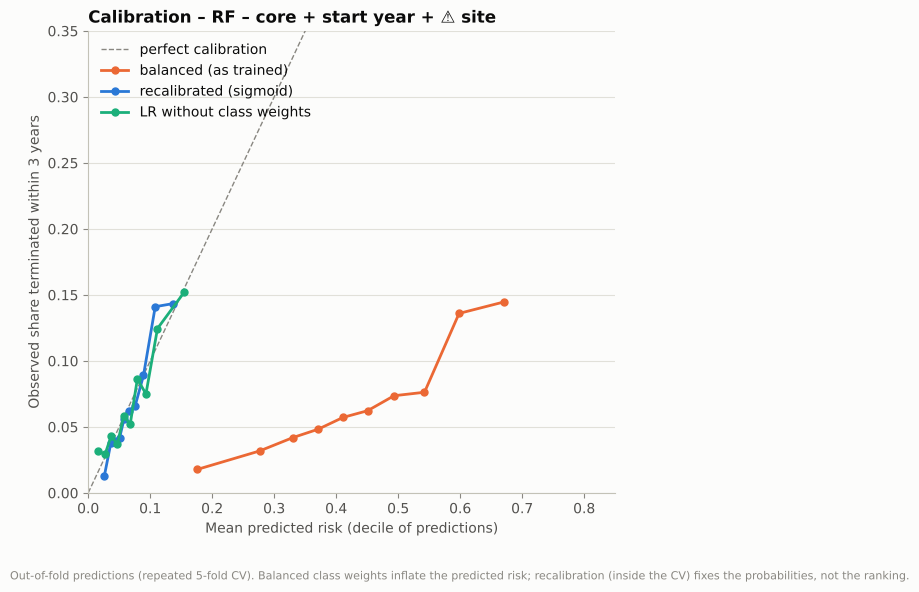

In [21]:
fig, ax = plt.subplots(figsize=(6.8, 6))
ax.plot([0, 0.6], [0, 0.6], color=vs.INK_MUTED, ls="--", lw=1, label="perfect calibration")
for (label, p), color in zip(cal_oof.items(), [vs.SERIES[1], vs.SERIES[0], vs.SERIES[2]]):
    frac, mean_pred = calibration_curve(y_all, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", markersize=5, color=color, label=label)
ax.set_xlabel("Mean predicted risk (decile of predictions)")
ax.set_ylabel("Observed share terminated within 3 years")
ax.set_xlim(0, max(0.85, max(cal_oof["balanced (as trained)"]) * 1.02))
ax.set_ylim(0, 0.35)
ax.legend(loc="upper left")
ax.set_title(f"Calibration – {best_name}")
vs.source_note(fig, "Out-of-fold predictions (repeated 5-fold CV). Balanced class weights inflate the predicted risk; "
               "recalibration (inside the CV) fixes the probabilities, not the ranking.", y=-0.02)
vs.save(fig, FIGURES / "diag_model_calibration.png")
plt.show()

### Temporal robustness test (train 2005–2015 → test 2017–2020)

Same tuning procedure (inner CV on the training period only). With start year the models must
extrapolate to unseen years – reported for completeness, but the variant **without** start year is
the more meaningful temporal test.

In [22]:
temp_rows = []
yt_test = test_t["y"].to_numpy()
boot_t = [rng.integers(0, len(yt_test), len(yt_test)) for _ in range(B)]
for name, kind, feats in configs:
    if kind is None:
        model = make_pipe(feats, DummyClassifier(strategy="prior") if name.startswith("Random") else LogisticRegression(max_iter=1000))
    else:
        model = tuned(kind, feats)
    model.fit(train_t[feats], train_t["y"])
    p = model.predict_proba(test_t[feats])[:, 1]
    vals = np.array([average_precision_score(yt_test[i], p[i]) for i in boot_t])
    temp_rows.append({"model": name, "PR-AUC test (95% CI)": f"{average_precision_score(yt_test, p):.3f} "
                                                         f"({np.percentile(vals, 2.5):.3f}–{np.percentile(vals, 97.5):.3f})",
                      "ROC-AUC test": round(roc_auc_score(yt_test, p), 3),
                      "top-10% terminated %": round(100 * top_decile_share(yt_test, p), 1)})
temporal = pd.DataFrame(temp_rows)
temporal.to_csv(PROCESSED / "table_model_performance_temporal.csv", index=False)
print(f"Test prevalence 2017–2020: {100 * yt_test.mean():.1f} %")
temporal

Test prevalence 2017–2020: 9.6 %


,model,PR-AUC test (95% CI),ROC-AUC test,top-10% terminated %
0,Random (prevalence),0.096 (0.084–0.107),0.500,9.2
1,Rule of thumb,0.098 (0.084–0.114),0.520,9.7
2,LR – core,0.126 (0.106–0.160),0.590,13.0
3,LR – core + start year,0.126 (0.105–0.159),0.590,13.0
4,LR – core + start year + ⚠️ site,0.146 (0.119–0.182),0.614,18.5
5,RF – core,0.133 (0.112–0.161),0.619,14.7
6,RF – core + start year,0.133 (0.111–0.162),0.616,14.3
7,RF – core + start year + ⚠️ site,0.169 (0.138–0.212),0.655,19.3


### Sensitivity: outcome of the analysis set (Completed vs. Terminated, start 2005–2022)

Not right-censoring-free (see Block 13); shown only to compare with the window target. Best model
configuration with the most frequent tuned parameters from the main nested CV (fixed), repeated
5-fold CV.

In [23]:
ana = pd.read_parquet(PROCESSED / "ctgov_analysis_dataset.parquet")
ya = ana["terminated"].to_numpy()
sens_rows = []
for name, kind, feats in [("Rule of thumb", None, ["oncology", "healthy_volunteers", "phase_1_2"]),
                          (best_name, best_kind, best_feats)]:
    ana["oncology"] = (ana["indication_group"] == "Oncology").astype(int)
    res = []
    for tr, te in CV.split(ana, ya):
        m = make_pipe(feats, LogisticRegression(max_iter=1000)) if kind is None else fixed_best()
        m.fit(ana.iloc[tr][feats], ya[tr])
        p = m.predict_proba(ana.iloc[te][feats])[:, 1]
        res.append(fold_metrics(ya[te], p))
    r = pd.DataFrame(res)
    sens_rows.append({"model": name, "prevalence %": round(100 * ya.mean(), 1), "PR-AUC CV": round(r["pr_auc"].mean(), 3),
                      "PR-AUC range": f"{r['pr_auc'].min():.3f}–{r['pr_auc'].max():.3f}",
                      "ROC-AUC CV": round(r["roc_auc"].mean(), 3), "top-10% terminated %": round(100 * r["top10"].mean(), 1)})
pd.DataFrame(sens_rows)

,model,prevalence %,PR-AUC CV,PR-AUC range,ROC-AUC CV,top-10% terminated %
0,Rule of thumb,14.5,0.247,0.228–0.282,0.698,30.7
1,RF – core + start year + ⚠️ site,14.5,0.390,0.346–0.431,0.761,45.7


Saved figure: 09_model_performance.png


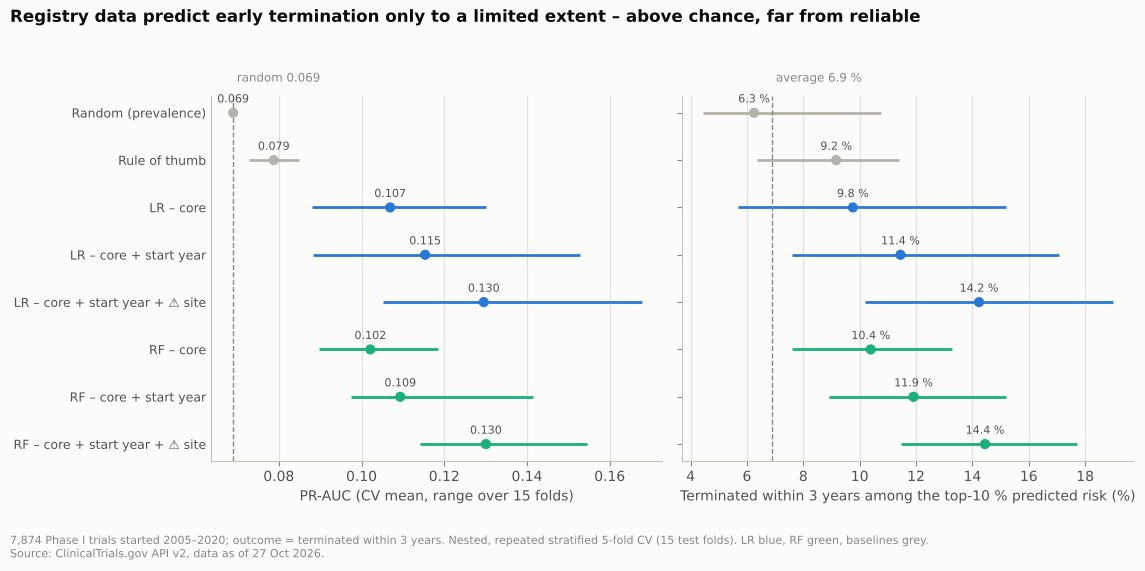

In [24]:
# Figure: PR-AUC and top-10 % termination share per model (CV), baselines for reference
order = list(oof)
f_ = folds.set_index("model").loc[order].reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2), sharey=True)
ypos = np.arange(len(order))[::-1]
colors = [vs.NEUTRAL if m.startswith(("Random", "Rule")) else vs.SERIES[0] if m.startswith("LR") else vs.SERIES[2] for m in order]
for ax, metric, xlabel, ref in [(axes[0], "pr_auc", "PR-AUC (CV mean, range over 15 folds)", y_all.mean()),
                                (axes[1], "top10", "Terminated within 3 years among the top-10 % predicted risk", y_all.mean())]:
    g = folds.groupby("model")[metric]
    mean_, lo_, hi_ = g.mean().loc[order], g.min().loc[order], g.max().loc[order]
    scale = 100 if metric == "top10" else 1
    ax.hlines(ypos, lo_ * scale, hi_ * scale, colors=colors, lw=2)
    ax.scatter(mean_ * scale, ypos, c=colors, s=40, zorder=3)
    ax.axvline(ref * scale, color=vs.INK_MUTED, ls="--", lw=1)
    ax.text(ref * scale, len(order) - 0.4, " average 6.9 %" if metric == "top10" else " random 0.069",
            color=vs.INK_MUTED, fontsize=8.5, va="bottom")
    for yy, m in zip(ypos, mean_ * scale):
        ax.text(m, yy + 0.22, f"{m:.1f} %" if metric == "top10" else f"{m:.3f}", ha="center", fontsize=8, color=vs.INK_SECONDARY)
    ax.set_xlabel(xlabel + (" (%)" if metric == "top10" else ""))
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
axes[0].set_yticks(ypos, order, fontsize=9)
axes[0].tick_params(axis="y", length=0)
fig.suptitle("Registry data predict early termination only to a limited extent – above chance, far from reliable",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
vs.source_note(fig, f"{len(cohort):,} Phase I trials started 2005–2020; outcome = terminated within 3 years. Nested, repeated "
               "stratified 5-fold CV (15 test folds). LR blue, RF green, baselines grey.\nSource: ClinicalTrials.gov API v2, data as of 27 Oct 2026.", y=-0.03)
fig.tight_layout(rect=(0, 0, 1, 0.95))
vs.save(fig, FIGURES / "09_model_performance.png")
plt.show()

In [25]:
pd.to_pickle({"oof": oof, "cal_oof": cal_oof, "best_name": best_name, "best_feats": best_feats,
              "splits": splits}, PROCESSED / "model_oof_predictions.pkl")
print("Saved OOF predictions for Block 17")

Saved OOF predictions for Block 17


## B. Summary (Block 16)

**Discrimination (nested repeated CV, outcome = terminated within 3 years, prevalence 6.9 %):**

| Model | PR-AUC (OOF, 95 % bootstrap CI) | ROC-AUC | Top 10 % risk: terminated |
|---|---|---|---|
| Random (prevalence) | 0.069 (0.062–0.077) | 0.50 | 6.3 % |
| Rule of thumb | 0.078 (0.070–0.088) | 0.55 | 9.2 % |
| LR / RF – core (✅ only) | 0.102 / 0.099 | 0.63 | 9.8 / 10.4 % |
| LR / RF – + start year | 0.109 / 0.106 | 0.64 | 11.4 / 11.9 % |
| **LR / RF – + start year + ⚠️ site** | **0.125 / 0.123** (≈ 0.11–0.15) | 0.66 / 0.67 | **14.2 / 14.4 %** |

* All models beat the rule of thumb (paired bootstrap Δ PR-AUC +0.02 to +0.05, CIs above 0).
* LR and RF perform alike – no gain from non-linear modelling.
* The site/country features (⚠️) add the largest share – but they may have been updated after
  the start; without them (core only) PR-AUC ≈ 0.10 and ROC-AUC ≈ 0.63.
* **Practical meaning:** among the 10 % of trials with the highest predicted risk, about 14 % are
  terminated within 3 years – twice the average (6.9 %), but 86 % of these "high-risk" trials
  still are not.

**Calibration:** balanced class weights inflate the mean predicted risk to 43 % (observed 6.9 %;
Brier 0.206). Recalibration inside the CV (sigmoid) restores calibration (mean 6.9 %, Brier
0.063), as does LR without class weights (0.063) – but the Brier score of simply predicting the
prevalence is 0.064: **the probabilities add hardly any information beyond the average risk.**

**Temporal test (2005–2015 → 2017–2020, test prevalence 9.6 %):** PR-AUC 0.13 (core) to 0.17
(RF with site features), ROC-AUC 0.59–0.66, top-10 % share 13–19 % – similar to the CV, i.e. the
modest signal is stable over time. The start year adds nothing in the temporal test (with strong
regularisation its coefficient is close to zero).

**Sensitivity (analysis-set outcome, prevalence 14.5 %):** PR-AUC 0.39 vs. 0.25 (rule of thumb),
ROC-AUC 0.76 – clearly higher, because this outcome also contains late terminations of long
(oncology, multinational) trials, which are easier to recognise, and it is affected by
right-censoring.

**Conclusion:** registry data **alone predict early termination of Phase I trials only to a
limited extent**. The models identify a group with about twice the average risk, but they are far
from reliable for individual trials – decisive reasons (portfolio decisions, emerging safety or
efficacy data, funding) are not contained in the registry at the start of a trial.

# Part C – Interpretation of the main model (Block 17)

**Main model (D56/D57):** logistic regression, core features + start year (no ⚠️ site features),
balanced class weights, regularisation C fixed at the most frequent nested-CV choice, **recalibrated**
(sigmoid, fitted inside each training fold). The model with ⚠️ site features (RF) is shown only as
an upper bound. All statements describe **associations** in registry data, not causal effects.

In [26]:
from sklearn.inspection import permutation_importance

MAIN_NAME = "LR – core + start year"
MAIN_FEATS = VARIANTS["core + start year"][0]
c_main = ast.literal_eval(pd.Series(best_params[MAIN_NAME]).value_counts().index[0])["model__C"]
print(f"Main model: {MAIN_NAME}, C = {c_main}")


def main_model():
    lr = make_pipe(MAIN_FEATS, LogisticRegression(class_weight="balanced", C=c_main, max_iter=3000))
    return CalibratedClassifierCV(lr, method="sigmoid", cv=3)


# Out-of-fold predictions of the recalibrated main model (same 15 outer folds as before)
main_preds = np.zeros((3, len(y_all)))
fold_models = []
for k, (tr, te) in enumerate(splits):
    m = main_model().fit(X_all.iloc[tr][MAIN_FEATS], y_all[tr])
    main_preds[k // 5, te] = m.predict_proba(X_all.iloc[te][MAIN_FEATS])[:, 1]
    fold_models.append(m)
main_oof = main_preds.mean(axis=0)
print(f"Recalibrated main model: PR-AUC (OOF) {average_precision_score(y_all, main_oof):.3f}, "
      f"ROC-AUC {roc_auc_score(y_all, main_oof):.3f}, mean predicted risk {100 * main_oof.mean():.1f} % "
      f"(observed {100 * y_all.mean():.1f} %), Brier {brier_score_loss(y_all, main_oof):.4f}")

Main model: LR – core + start year, C = 0.01


Recalibrated main model: PR-AUC (OOF) 0.110, ROC-AUC 0.642, mean predicted risk 6.9 % (observed 6.9 %), Brier 0.0632


## C1. Threshold: the scenario "flag the top 10 %"

Within every test fold the 10 % of trials with the highest predicted risk are flagged. Counts are
summed over the 5 folds of each repeat (every trial is tested once per repeat) and averaged over
the 3 repeats, then scaled to **1,000 trials**.

In [27]:
def flag_scenario(preds_by_rep, share):
    rows = []
    for rep in range(3):
        tp = fp = fn = tn = 0
        for k in range(rep * 5, rep * 5 + 5):
            te = splits[k][1]
            p, y = preds_by_rep[rep, te], y_all[te]
            n_flag = int(round(share * len(te)))
            flag = np.zeros(len(te), bool)
            flag[np.argsort(-p)[:n_flag]] = True
            tp += int((flag & (y == 1)).sum()); fp += int((flag & (y == 0)).sum())
            fn += int((~flag & (y == 1)).sum()); tn += int((~flag & (y == 0)).sum())
        rows.append((tp, fp, fn, tn))
    tp, fp, fn, tn = np.mean(rows, axis=0)
    n = tp + fp + fn + tn
    return {"flagged": f"{int(100 * share)} %", "precision %": 100 * tp / (tp + fp), "recall %": 100 * tp / (tp + fn),
            "per 1,000 trials: flagged": 1000 * (tp + fp) / n, "correctly flagged (TP)": 1000 * tp / n,
            "wrongly flagged (FP)": 1000 * fp / n, "missed terminations (FN)": 1000 * fn / n,
            "_cm": np.array([[tn, fp], [fn, tp]]) * 1000 / n}


rf_upper = pd.read_pickle(PROCESSED / "model_oof_predictions.pkl")
thr_rows = []
for label, preds in [("main: LR core + start year (recalibrated)", main_preds)]:
    for share in [0.05, 0.10, 0.20, 0.30]:
        thr_rows.append({"model": label, **flag_scenario(preds, share)})
# Upper bound: RF with ⚠️ site features (OOF averaged; folds evaluated on the averaged predictions)
ub = np.tile(oof["RF – core + start year + ⚠️ site"], (3, 1))
thr_rows.append({"model": "upper bound: RF + ⚠️ site", **flag_scenario(ub, 0.10)})
thr = pd.DataFrame(thr_rows)
thr.drop(columns="_cm").round(1)

,model,flagged,precision %,recall %,"per 1,000 trials: flagged",correctly flagged (TP),wrongly flagged (FP),missed terminations (FN)
0,main: LR core + start year (recalibrated),5 %,11.8,8.6,50.2,5.9,44.2,63.0
1,main: LR core + start year (recalibrated),10 %,11.5,16.8,100.2,11.6,88.6,57.4
2,main: LR core + start year (recalibrated),20 %,11.7,33.8,200.0,23.3,176.7,45.6
3,main: LR core + start year (recalibrated),30 %,11.0,47.6,299.7,32.9,266.9,36.1
4,upper bound: RF + ⚠️ site,10 %,14.5,21.1,100.2,14.6,85.6,54.4


Saved figure: 10_top10_confusion_matrix.png


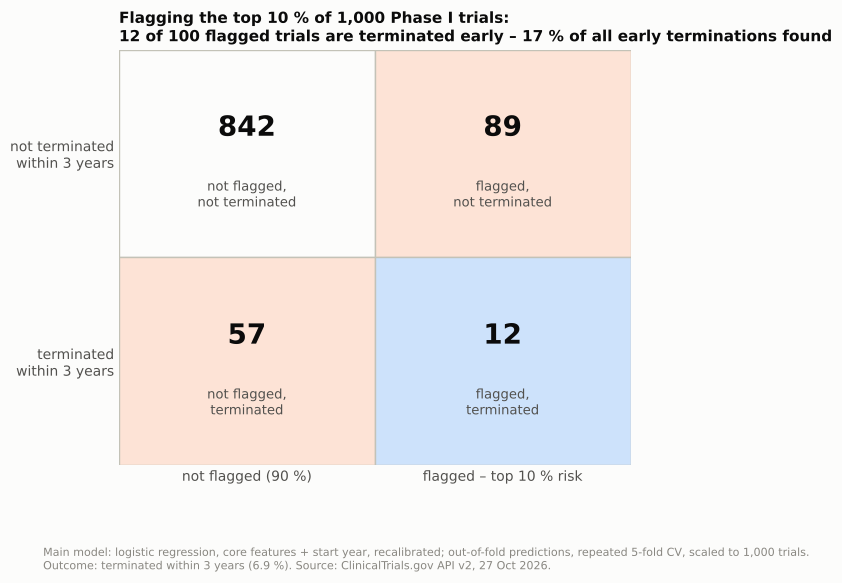

In [28]:
cm = thr[(thr["model"].str.startswith("main")) & (thr["flagged"] == "10 %")]["_cm"].iloc[0]
fig, ax = plt.subplots(figsize=(6.6, 5.4))
ax.grid(False)
colors_cm = np.array([[vs.SURFACE, "#fde3d6"], ["#fde3d6", "#cde2fb"]])
labels_cm = [["not flagged,\nnot terminated", "flagged,\nnot terminated"], ["not flagged,\nterminated", "flagged,\nterminated"]]
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, facecolor=colors_cm[i, j], edgecolor=vs.BASELINE, lw=1))
        ax.text(j + 0.5, 1 - i + 0.62, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=20, fontweight="bold",
                color=vs.INK_PRIMARY)
        ax.text(j + 0.5, 1 - i + 0.3, labels_cm[i][j], ha="center", va="center", fontsize=9.5, color=vs.INK_SECONDARY)
ax.set_xlim(0, 2); ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5], ["not flagged (90 %)", "flagged – top 10 % risk"])
ax.set_yticks([1.5, 0.5], ["not terminated\nwithin 3 years", "terminated\nwithin 3 years"])
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
r = thr[(thr["model"].str.startswith("main")) & (thr["flagged"] == "10 %")].iloc[0]
ax.set_title(f"Flagging the top 10 % of 1,000 Phase I trials:\n{r['correctly flagged (TP)']:.0f} of "
             f"{r['per 1,000 trials: flagged']:.0f} flagged trials are terminated early – "
             f"{r['recall %']:.0f} % of all early terminations found", fontsize=11)
vs.source_note(fig, "Main model: logistic regression, core features + start year, recalibrated; out-of-fold predictions, "
               "repeated 5-fold CV, scaled to 1,000 trials.\nOutcome: terminated within 3 years (6.9 %). "
               "Source: ClinicalTrials.gov API v2, 27 Oct 2026.", y=-0.04)
vs.save(fig, FIGURES / "10_top10_confusion_matrix.png")
plt.show()

## C2. Permutation importance on the test folds

Drop in PR-AUC on each test fold when a feature (or a group of correlated features) is randomly
shuffled; the model fitted on the corresponding training fold is kept fixed. 15 test folds × 5
shuffles; mean ± SD across folds. **Grouped** importance shuffles correlated features together
(e.g. the design cluster), so that they cannot mask each other.

In [29]:
GROUPS = {
    "Design cluster (placebo, blinded, randomised)": ["placebo", "blinded", "randomized"],
    "Population (healthy volunteers, children, male only)": ["healthy_volunteers", "includes_children", "male_only"],
    "Indication group": ["indication_group"],
    "Phase 1/2": ["phase_1_2"],
    "Sponsor (type, industry collaborator)": ["sponsor_group", "industry_collaborator"],
    "Intervention (model, biological, drug)": ["intervention_model", "biological", "drug"],
    "Purpose & DMC (incl. 'not reported')": ["primary_purpose_group", "has_dmc_cat"],
    "Start year": ["start_year"],
}
rng_p = np.random.default_rng(SEED)
single_rows, group_rows = [], []
for k, (tr, te) in enumerate(splits):
    m = fold_models[k]
    Xte, yte = X_all.iloc[te][MAIN_FEATS].reset_index(drop=True), y_all[te]
    base_score = average_precision_score(yte, m.predict_proba(Xte)[:, 1])
    for name, cols in list(GROUPS.items()) + [(f, [f]) for f in MAIN_FEATS]:
        drops = []
        for _ in range(5):
            Xp = Xte.copy()
            perm = rng_p.permutation(len(Xp))
            Xp[cols] = Xp[cols].iloc[perm].to_numpy()     # shuffle the group jointly (rows kept together)
            drops.append(base_score - average_precision_score(yte, m.predict_proba(Xp)[:, 1]))
        (group_rows if name in GROUPS else single_rows).append({"feature": name, "fold": k, "drop": np.mean(drops)})

def summarise(rows):
    d = pd.DataFrame(rows).groupby("feature")["drop"].agg(["mean", "std", "min", "max"])
    return d.sort_values("mean", ascending=False)

imp_group = summarise(group_rows)
imp_single = summarise(single_rows)
imp_group.to_csv(PROCESSED / "table_permutation_importance_groups.csv")
imp_single.to_csv(PROCESSED / "table_permutation_importance_single.csv")
print(f"Baseline PR-AUC of the main model ≈ {average_precision_score(y_all, main_oof):.3f}")
imp_group.round(4)

Baseline PR-AUC of the main model ≈ 0.110


,mean,std,min,max
feature,,,,
"Design cluster (placebo, blinded, randomised)",0.0186,0.0164,0.0007,0.0562
Start year,0.0125,0.0118,-0.0042,0.0342
"Sponsor (type, industry collaborator)",0.0122,0.0063,0.0025,0.0293
"Intervention (model, biological, drug)",0.0060,0.0081,-0.0113,0.0232
Indication group,0.0035,0.0078,-0.0092,0.0177
Purpose & DMC (incl. 'not reported'),0.0009,0.0028,-0.0042,0.0064
Phase 1/2,0.0007,0.0062,-0.0078,0.0155
"Population (healthy volunteers, children, male only)",0.0005,0.0062,-0.0130,0.0138


In [30]:
imp_single.round(4).head(12)

,mean,std,min,max
feature,,,,
placebo,0.0212,0.0155,-0.0004,0.0613
start_year,0.0130,0.0102,-0.0013,0.0384
sponsor_group,0.0121,0.0073,-0.0036,0.0282
randomized,0.0042,0.0061,-0.0051,0.0162
indication_group,0.0038,0.0084,-0.0086,0.0195
biological,0.0026,0.0023,-0.0007,0.0082
intervention_model,0.0024,0.0035,-0.0062,0.0087
healthy_volunteers,0.0022,0.0057,-0.0083,0.0128
blinded,0.0017,0.0038,-0.0025,0.0130


Saved figure: 11_feature_importance.png


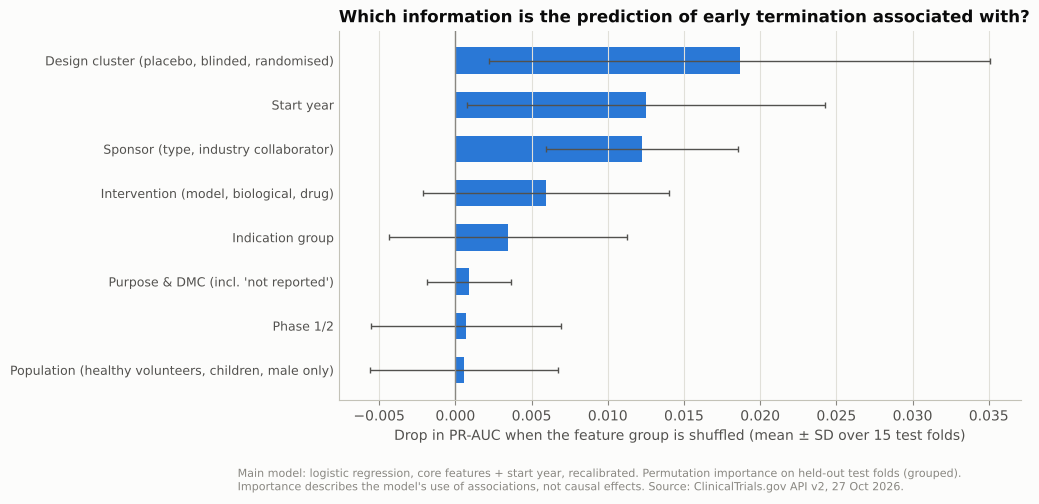

In [31]:
fig, ax = plt.subplots(figsize=(8.8, 4.8))
g = imp_group.sort_values("mean")
y = np.arange(len(g))
ax.barh(y, g["mean"], xerr=g["std"], color=vs.SERIES[0], height=0.6, error_kw={"ecolor": vs.INK_SECONDARY, "elinewidth": 1, "capsize": 2.5})
ax.axvline(0, color=vs.INK_MUTED, lw=1)
ax.set_yticks(y, g.index, fontsize=9)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Drop in PR-AUC when the feature group is shuffled (mean ± SD over 15 test folds)")
ax.set_title("Which information is the prediction of early termination associated with?")
vs.source_note(fig, "Main model: logistic regression, core features + start year, recalibrated. Permutation importance on held-out test folds "
               "(grouped).\nImportance describes the model's use of associations, not causal effects. Source: ClinicalTrials.gov API v2, 27 Oct 2026.", y=-0.03)
vs.save(fig, FIGURES / "11_feature_importance.png")
plt.show()

## C3. Odds ratios of the main-model features and the design cluster (D52, D50)

For interpretation the same features are fitted in an **unpenalised** logistic regression on the
whole cohort (statsmodels; the regularised prediction model shrinks coefficients towards 0). The
design cluster is evaluated **jointly**: a joint Wald test for placebo + blinded + randomised and
the combined contrast "randomised, double-blind, placebo-controlled vs. open-label,
non-randomised, no placebo".

In [32]:
f_main = ("y ~ " + " + ".join([f"C({c})" for c in CAT if c in MAIN_FEATS] + [f for f in MAIN_FEATS if f not in CAT]))
lr_sm = smf.logit(f_main, data=cohort).fit(disp=False, maxiter=300)
ors = pd.DataFrame({"OR": np.exp(lr_sm.params), "CI low": np.exp(lr_sm.conf_int()[0]),
                    "CI high": np.exp(lr_sm.conf_int()[1]), "p": lr_sm.pvalues}).drop("Intercept")
ors.index = ors.index.str.replace(r"C\((\w+)\)\[T\.(.*)\]", r"\1: \2", regex=True)
ors["OR (95% CI)"] = ors.apply(lambda r: f"{r['OR']:.2f} ({r['CI low']:.2f}–{r['CI high']:.2f})", axis=1)
ors[["OR (95% CI)", "p"]].to_csv(PROCESSED / "table_main_model_odds_ratios.csv")

design = ["placebo", "blinded", "randomized"]
wald = lr_sm.wald_test(" , ".join(f"{d} = 0" for d in design), scalar=True)
b, V = lr_sm.params, lr_sm.cov_params()
est = b[design].sum(); se = np.sqrt(V.loc[design, design].to_numpy().sum())
print(f"Design cluster – joint Wald test: chi² = {wald.statistic:.1f}, df = 3, p = {wald.pvalue:.2g}")
print(f"Randomised double-blind placebo-controlled vs. open non-randomised without placebo: "
      f"OR {np.exp(est):.2f} ({np.exp(est - 1.96 * se):.2f}–{np.exp(est + 1.96 * se):.2f})")
ors[["OR (95% CI)", "p"]].round(4)

Design cluster – joint Wald test: chi² = 35.6, df = 3, p = 9.3e-08
Randomised double-blind placebo-controlled vs. open non-randomised without placebo: OR 2.02 (1.51–2.70)


,OR (95% CI),p
indication_group: Healthy volunteers – no target condition,0.78 (0.44–1.40),0.4048
indication_group: Immunology & inflammation,1.01 (0.54–1.86),0.9812
indication_group: Infectious diseases & vaccines,1.03 (0.55–1.94),0.9216
indication_group: Metabolic & endocrine,0.63 (0.32–1.22),0.1726
indication_group: Nervous system & mental disorders,1.09 (0.61–1.94),0.7718
indication_group: Oncology,1.32 (0.77–2.28),0.3160
indication_group: Other diseases,1.09 (0.60–1.98),0.7880
indication_group: Respiratory,0.76 (0.38–1.50),0.4281
sponsor_group: Government / network / other,1.15 (0.45–2.95),0.7635
sponsor_group: Industry,1.91 (1.48–2.48),0.0000


In [33]:
# Placebo finding (D50): design-cluster contrast separately for healthy-volunteer and patient trials
rows_d = []
for hv, pop in [(1, "Healthy volunteers"), (0, "Patients")]:
    d = cohort[cohort["healthy_volunteers"] == hv]
    if hv == 0:
        d = d.assign(indication_group=d["indication_group"].replace({"Healthy volunteers – no target condition": "Other diseases"}))
    # industry yes/no instead of the 3-level sponsor variable (0 early terminations in the small
    # government/network group of healthy-volunteer trials -> quasi-separation)
    feats = [("industry_sponsor" if f == "sponsor_group" else f) for f in MAIN_FEATS if f != "healthy_volunteers"]
    # further sparse cells without any early termination: children in healthy-volunteer trials (0/49),
    # factorial design in patient trials (0/21 -> merged with parallel)
    if hv == 1:
        feats = [f for f in feats if f != "includes_children"]
    else:
        d = d.assign(intervention_model=d["intervention_model"].replace({"FACTORIAL": "PARALLEL"}))
    fm = "y ~ " + " + ".join([f"C({c})" for c in CAT if c in feats] + [f for f in feats if f not in CAT])
    r_ = smf.logit(fm, data=d).fit(disp=False, maxiter=300)
    e = r_.params[design].sum(); s = np.sqrt(r_.cov_params().loc[design, design].to_numpy().sum())
    rows_d.append({"population": pop, "trials": len(d), "early terminations": int(d["y"].sum()),
                   "OR placebo (adjusted)": f"{np.exp(r_.params['placebo']):.2f} ({np.exp(r_.conf_int().loc['placebo', 0]):.2f}–{np.exp(r_.conf_int().loc['placebo', 1]):.2f})",
                   "OR design cluster (RDBPC vs open)": f"{np.exp(e):.2f} ({np.exp(e - 1.96 * s):.2f}–{np.exp(e + 1.96 * s):.2f})"})
pd.DataFrame(rows_d)

,population,trials,early terminations,OR placebo (adjusted),OR design cluster (RDBPC vs open)
0,Healthy volunteers,3383,192,3.83 (2.03–7.23),2.25 (1.43–3.53)
1,Patients,4491,351,1.30 (0.73–2.31),1.52 (0.99–2.34)


## C4. Summary (Block 17) – associations, not causal effects

**Main model** (LR, core features + start year, recalibrated): PR-AUC 0.110, ROC-AUC 0.64, mean
predicted risk 6.9 % = observed, Brier 0.063.

**Scenario "flag the top 10 %" (per 1,000 trials):** 100 flagged, of which **12 are terminated
within 3 years (precision 11.5 %, vs. 6.9 % on average)** and **89 are flagged wrongly**; 12 of 69
early terminations are found (**recall 17 %**), 57 are missed. Flagging more trials raises recall
(5 %: 9 % · 20 %: 34 % · 30 %: 48 %) but precision stays at about 11–12 % – the model ranks risk
only weakly. Upper bound (RF with ⚠️ site features): precision 14.5 %, recall 21 %.

**Permutation importance (grouped, 15 test folds):** the **design cluster** (placebo, blinded,
randomised) contributes most (PR-AUC drop 0.019 ± 0.016), followed by **start year** (0.013 ± 0.012)
and **sponsor** (0.012 ± 0.006). Intervention model, indication, purpose/DMC, Phase 1/2 and
population contribute little – their spread across folds includes 0. Within the design cluster
the placebo indicator carries the signal.

**Odds ratios** (unpenalised LR, same features, outcome terminated within 3 years):
* design cluster jointly significant (Wald χ² = 35.6, df 3, p < 0.001); randomised double-blind
  placebo-controlled vs. open-label non-randomised trials: **OR 2.02 (1.51–2.70)**;
* industry sponsor vs. academic: **OR 1.91 (1.48–2.48)**;
* start year: **OR 1.05 per year (1.03–1.08)** – about 1.6 per decade (cf. Block 13);
* intervention model vs. crossover: single group 2.16, parallel 1.86, sequential 1.65 – crossover
  PK/BE studies are rarely terminated early;
* "not reported" categories act as data-quality / older-record proxies (intervention model not
  reported OR 4.00; primary purpose not reported 0.26) – not interpreted as design effects;
* indication group and healthy volunteers are **not** independently associated with *early*
  termination once design and sponsor are accounted for (oncology OR 1.32, 0.77–2.28) – unlike
  the overall termination share (Blocks 11–13), which also contains late terminations of long
  oncology trials.

**Placebo finding (D50):** the association sits in **healthy-volunteer trials** (placebo OR 3.83,
2.03–7.23; design cluster 2.25, 1.43–3.53) and is weak in patient trials (placebo 1.30, 0.73–2.31;
design cluster 1.52, 0.99–2.34). Consistent with Block 15: in healthy volunteers, randomised
double-blind placebo-controlled designs mark early (often first-in-human, dose-escalation)
development of new compounds with high attrition; open-label crossover PK/BE/DDI studies of known
drugs are rarely terminated. Within healthy-volunteer trials, these FIH-like designs carry the
highest early-termination risk (9.2 % vs. 3.0 %) – overall, oncology remains higher (D54).